In [1]:
import sys
!{sys.executable} -m pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import xgboost

print("XGBoost Version:", xgboost.__version__)
print("XGBoost Installed Successfully")

XGBoost Version: 3.4.1
XGBoost Installed Successfully


In [4]:
import os

print("Current Folder:", os.getcwd())
print("\nFiles Available:")
print(os.listdir())

Current Folder: c:\Users\ADMIN\Desktop\week2_day5_task3

Files Available:
['task3_xgboost.ipynb']


In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("========== DATASET LOADING ==========")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nChurn Distribution:")
print(df["Churn"].value_counts())

========== DATASET LOADING ==========
Dataset Shape: (7043, 21)

First 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["Churn"]
)

print("========== DATA SPLITTING ==========")
print("Dataset Shape:", df.shape)
print("Training Data:", train_df.shape)
print("Testing Data:", test_df.shape)

print("\nTraining Churn Distribution:")
print(train_df["Churn"].value_counts())

========== DATA SPLITTING ==========
Dataset Shape: (7043, 21)
Training Data: (5634, 21)
Testing Data: (1409, 21)

Training Churn Distribution:
Churn
No     4139
Yes    1495
Name: count, dtype: int64


In [7]:
print("========== FEATURE ENGINEERING ==========")

X_train = train_df.drop(columns=["Churn", "customerID"])
y_train = train_df["Churn"].map({"No": 0, "Yes": 1})

X_test = test_df.drop(columns=["Churn", "customerID"])
y_test = test_df["Churn"].map({"No": 0, "Yes": 1})

print("Training Features Shape:", X_train.shape)
print("Training Target Shape:", y_train.shape)

print("\nTesting Features Shape:", X_test.shape)
print("Testing Target Shape:", y_test.shape)

print("\nTarget Distribution:")
print(y_train.value_counts())

========== FEATURE ENGINEERING ==========
Training Features Shape: (5634, 19)
Training Target Shape: (5634,)

Testing Features Shape: (1409, 19)
Testing Target Shape: (1409,)

Target Distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("========== PREPROCESSING ==========")
print("Numeric Features:", numeric_features)
print("Categorical Features:", categorical_features)
print("Preprocessing Pipeline Created Successfully")


========== PREPROCESSING ==========
Numeric Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Preprocessing Pipeline Created Successfully


In [9]:
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric="logloss"
    ))
])

print("========== XGBOOST MODEL ==========")
print("Scale Pos Weight:", round(scale_pos_weight, 2))
print("XGBoost Pipeline Created Successfully")

========== XGBOOST MODEL ==========
Scale Pos Weight: 2.77
XGBoost Pipeline Created Successfully


========== DATASET LOADING ==========
Dataset Shape: (7043, 21)
Training Data: (5634, 19)
Testing Data: (1409, 19)

========== VALIDATION SPLIT ==========

========== MODEL PIPELINES ==========
Logistic Regression Pipeline Created
Random Forest Pipeline Created
XGBoost Pipeline Created
Scale Pos Weight: 2.77

========== RANDOMIZED SEARCH CV ==========
Tuning Logistic Regression...
Best Logistic Regression Parameters:
{'model__solver': 'lbfgs', 'model__class_weight': None, 'model__C': 10}
Best ROC-AUC: 0.8438

Tuning Random Forest...
Best Random Forest Parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_depth': None, 'model__class_weight': 'balanced_subsample'}
Best ROC-AUC: 0.8369

========== MODEL COMPARISON ==========
              Model  ROC-AUC  F1 Score
Logistic Regression   0.8486    0.6131
      Random Forest   0.8400    0.6338
            XGBoost   0.8494    0.6275

Comparison table saved.

========== ROC CURVE =====

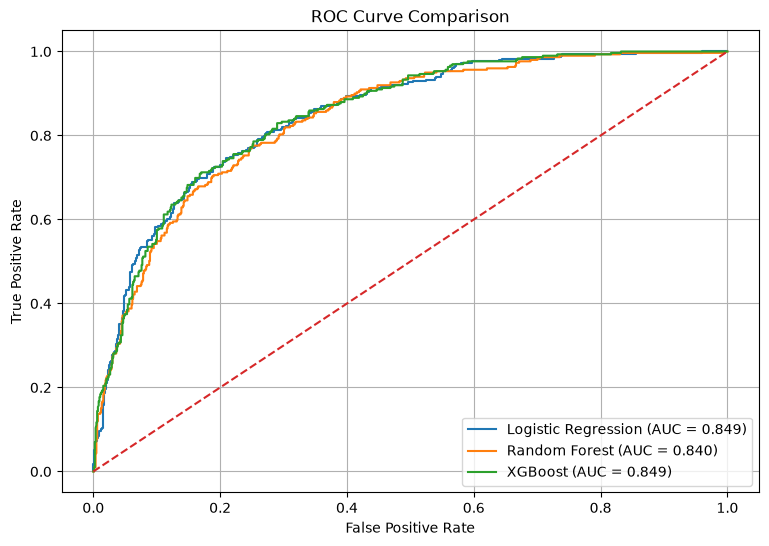

ROC chart saved.

========== BEST MODEL SELECTION ==========
Best Model: XGBoost

========== BUSINESS THRESHOLD SELECTION ==========
Selected Threshold: 0.5446
Churn Recall: 0.7559
Churn Precision: 0.5526

========== FEATURE IMPORTANCE ==========

Top 5 Important Features:
        Feature  Importance
       Contract    0.098513
         tenure    0.065671
 MonthlyCharges    0.016240
InternetService    0.014091
 OnlineSecurity    0.009475


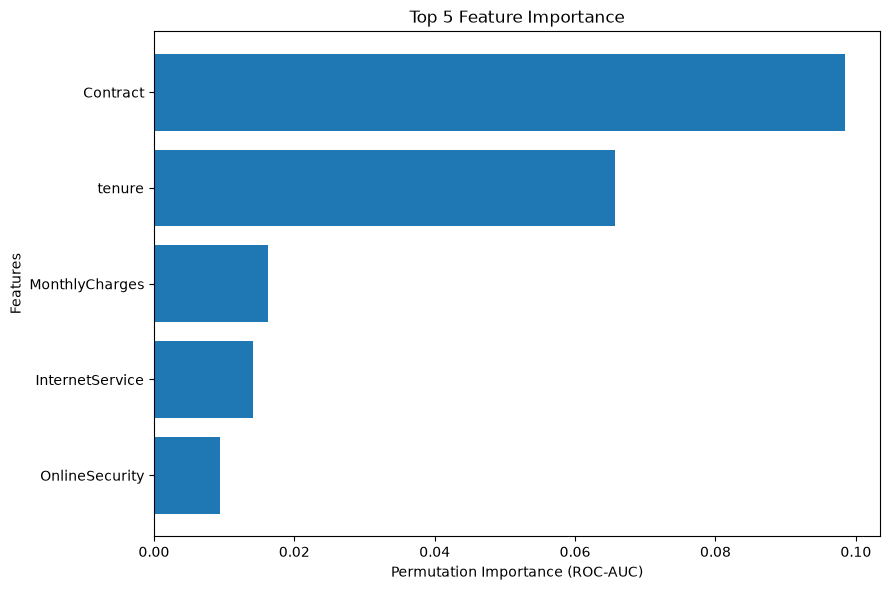

Feature importance chart saved.

========== BUSINESS EXPLANATION ==========
Contract: Contract type can influence customer loyalty.
tenure: Customer relationship duration affects retention.
MonthlyCharges: Monthly cost may influence cancellation decisions.
InternetService: Internet service type may affect satisfaction.
OnlineSecurity: Security service availability may influence retention.

========== TASK 1 COMPLETED ==========
Comparison table: task1_model_comparison.csv
ROC chart: task1_roc_curve.png
Feature chart: task1_feature_importance.png
Held-out test data has not been used.


In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, f1_score, roc_curve, precision_recall_curve
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier

print("========== DATASET LOADING ==========")

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Dataset Shape:", df.shape)

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["Churn"]
)

X_train = train_df.drop(columns=["Churn", "customerID"])
y_train = train_df["Churn"].map({"No": 0, "Yes": 1})

X_test = test_df.drop(columns=["Churn", "customerID"])
y_test = test_df["Churn"].map({"No": 0, "Yes": 1})

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\n========== VALIDATION SPLIT ==========")

X_model, X_valid, y_model, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

numeric_features = X_model.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = [
    col for col in X_model.columns
    if col not in numeric_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("\n========== MODEL PIPELINES ==========")

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

scale_pos_weight = (y_model == 0).sum() / (y_model == 1).sum()

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

print("Logistic Regression Pipeline Created")
print("Random Forest Pipeline Created")
print("XGBoost Pipeline Created")
print("Scale Pos Weight:", round(scale_pos_weight, 2))

print("\n========== RANDOMIZED SEARCH CV ==========")

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

logistic_params = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"],
    "model__solver": ["liblinear", "lbfgs"]
}

rf_params = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__class_weight": [None, "balanced", "balanced_subsample"]
}

logistic_search = RandomizedSearchCV(
    logistic_pipeline,
    logistic_params,
    n_iter=8,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

rf_search = RandomizedSearchCV(
    rf_pipeline,
    rf_params,
    n_iter=8,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

print("Tuning Logistic Regression...")
logistic_search.fit(X_model, y_model)

print("Best Logistic Regression Parameters:")
print(logistic_search.best_params_)
print("Best ROC-AUC:", round(logistic_search.best_score_, 4))

print("\nTuning Random Forest...")
rf_search.fit(X_model, y_model)

print("Best Random Forest Parameters:")
print(rf_search.best_params_)
print("Best ROC-AUC:", round(rf_search.best_score_, 4))

print("\n========== MODEL COMPARISON ==========")

models = {
    "Logistic Regression": logistic_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_,
    "XGBoost": xgb_pipeline
}

comparison_results = []
probabilities = {}

for name, model in models.items():

    model.fit(X_model, y_model)

    y_prob = model.predict_proba(X_valid)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    probabilities[name] = y_prob

    comparison_results.append({
        "Model": name,
        "ROC-AUC": round(roc_auc_score(y_valid, y_prob), 4),
        "F1 Score": round(f1_score(y_valid, y_pred), 4)
    })

results_df = pd.DataFrame(comparison_results)

print(results_df.to_string(index=False))

results_df.to_csv("task1_model_comparison.csv", index=False)

print("\nComparison table saved.")

print("\n========== ROC CURVE ==========")

plt.figure(figsize=(9, 6))

for name, y_prob in probabilities.items():

    fpr, tpr, thresholds = roc_curve(y_valid, y_prob)

    auc_score = roc_auc_score(y_valid, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.savefig("task1_roc_curve.png")
plt.show()

print("ROC chart saved.")

print("\n========== BEST MODEL SELECTION ==========")

best_model_name = results_df.loc[
    results_df["ROC-AUC"].idxmax(), "Model"
]

best_model = models[best_model_name]
best_probabilities = probabilities[best_model_name]

print("Best Model:", best_model_name)

print("\n========== BUSINESS THRESHOLD SELECTION ==========")

precision, recall, thresholds = precision_recall_curve(
    y_valid,
    best_probabilities
)

eligible = np.where(recall[:-1] >= 0.75)[0]

if len(eligible) > 0:
    best_index = eligible[
        np.argmax(precision[:-1][eligible])
    ]
    best_threshold = thresholds[best_index]
else:
    best_threshold = 0.5

threshold_predictions = (
    best_probabilities >= best_threshold
).astype(int)

print("Selected Threshold:", round(best_threshold, 4))
print("Churn Recall:", round(
    np.sum((threshold_predictions == 1) & (y_valid == 1)) /
    np.sum(y_valid == 1), 4
))
print("Churn Precision:", round(
    np.sum((threshold_predictions == 1) & (y_valid == 1)) /
    max(np.sum(threshold_predictions == 1), 1), 4
))

print("\n========== FEATURE IMPORTANCE ==========")

importance = permutation_importance(
    best_model,
    X_valid,
    y_valid,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_valid.columns,
    "Importance": importance.importances_mean
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

top_features = importance_df.head(5)

print("\nTop 5 Important Features:")
print(top_features.to_string(index=False))

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Permutation Importance (ROC-AUC)")
plt.ylabel("Features")
plt.title("Top 5 Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("task1_feature_importance.png")
plt.show()

print("Feature importance chart saved.")

print("\n========== BUSINESS EXPLANATION ==========")

business_explanations = {
    "tenure": "Customer relationship duration affects retention.",
    "Contract": "Contract type can influence customer loyalty.",
    "MonthlyCharges": "Monthly cost may influence cancellation decisions.",
    "TotalCharges": "Total customer spending reflects customer value.",
    "InternetService": "Internet service type may affect satisfaction.",
    "OnlineSecurity": "Security service availability may influence retention.",
    "TechSupport": "Technical support can improve customer satisfaction.",
    "PaymentMethod": "Payment preferences may relate to churn behaviour.",
    "PaperlessBilling": "Billing preferences may influence customer experience.",
    "SeniorCitizen": "Customer segment may show different churn patterns.",
    "Partner": "Household relationship status may relate to retention.",
    "Dependents": "Dependent status may relate to customer needs."
}

for _, row in top_features.iterrows():
    feature = row["Feature"]
    explanation = business_explanations.get(
        feature,
        "This feature helps distinguish customers who may leave."
    )
    print(feature + ":", explanation)

print("\n========== TASK 1 COMPLETED ==========")
print("Comparison table: task1_model_comparison.csv")
print("ROC chart: task1_roc_curve.png")
print("Feature chart: task1_feature_importance.png")
print("Held-out test data has not been used.")
